# Experiment 20: Future Sales Prediction
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement **Future Sales Prediction** using a suitable machine-learning algorithm.

The task: predict product sales from planned advertising spend on TV, Radio and Newspaper (regression), and use the trained model to forecast sales for *future* budget plans.

## Note on the data
A **synthetic advertising data set** (same structure as the well-known `Advertising.csv`: TV, Radio, Newspaper -> Sales) is generated with a fixed seed. To use the real file, replace the data cell with `df = pd.read_csv('Advertising.csv')`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(11)
n = 400
df = pd.DataFrame({
    'TV': rng.uniform(1, 300, n).round(1),
    'Radio': rng.uniform(0, 50, n).round(1),
    'Newspaper': rng.uniform(0, 100, n).round(1),
})
df['Sales'] = (3.0 + 0.046 * df.TV + 0.19 * df.Radio + 0.002 * df.Newspaper
               + 0.00004 * df.TV * df.Radio + rng.normal(0, 1.0, n)).round(2)
df.to_csv('advertising_synthetic.csv', index=False)
print(df.shape)
df.head()

(400, 4)


,TV,Radio,Newspaper,Sales
0,39.4,28.8,3.3,9.46
1,150.3,34.1,94.7,18.49
2,180.8,19.3,23.0,14.64
3,9.6,17.2,61.0,8.78
4,45.2,28.8,22.2,11.19


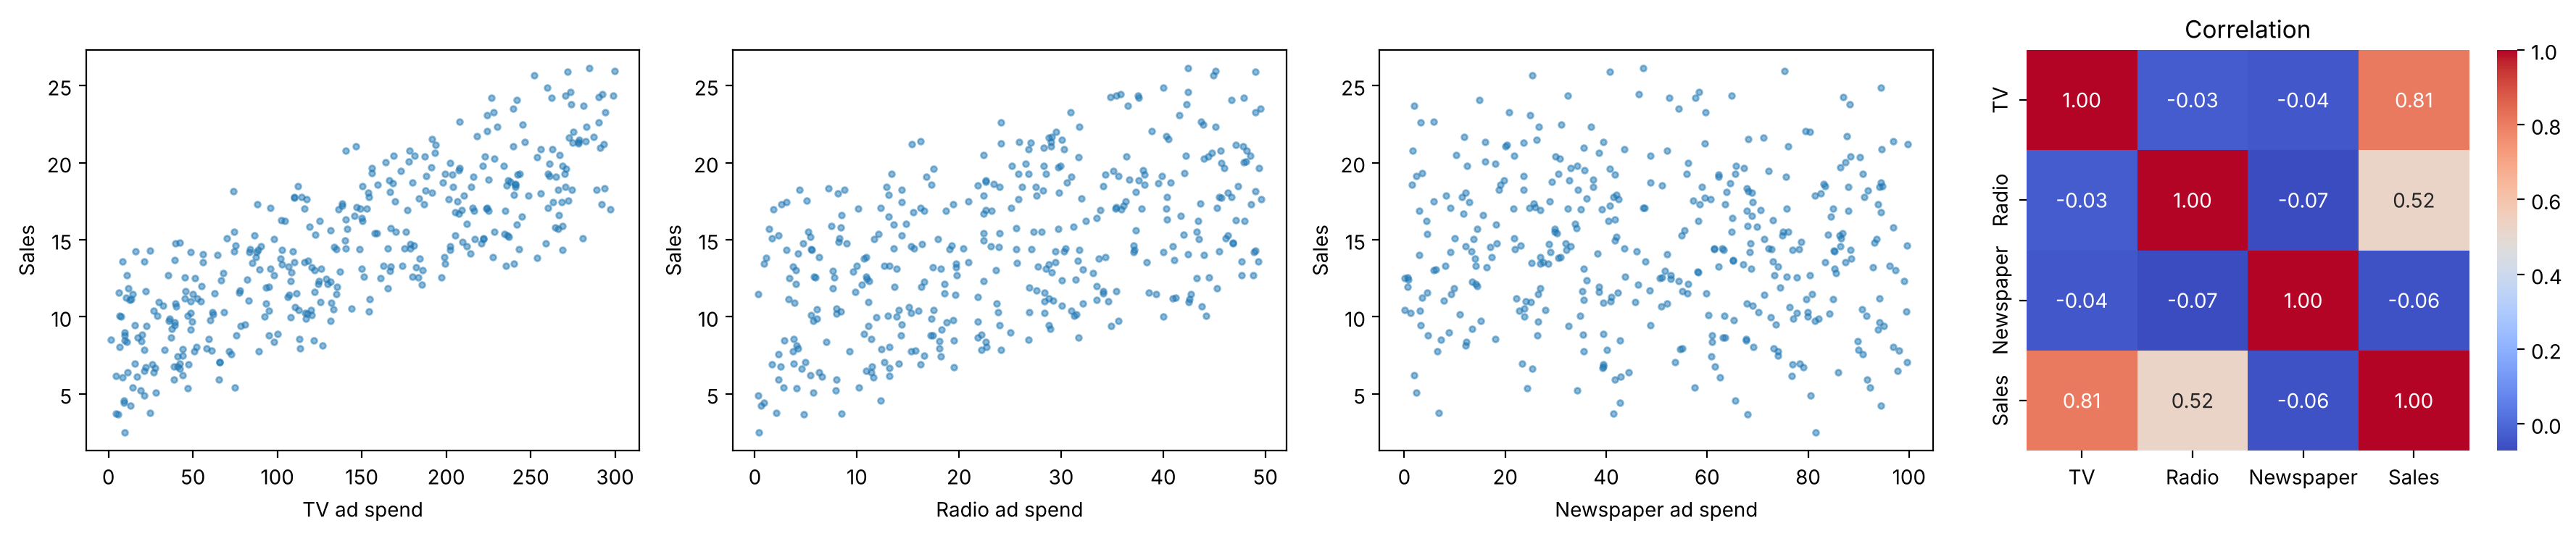

In [2]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, col in zip(ax[:3], ['TV', 'Radio', 'Newspaper']):
    a.scatter(df[col], df['Sales'], s=8, alpha=0.5); a.set_xlabel(col + ' ad spend'); a.set_ylabel('Sales')
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[3]); ax[3].set_title('Correlation')
plt.tight_layout(); plt.show()

In [3]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X, y = df[['TV', 'Radio', 'Newspaper']], df['Sales']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {'Linear Regression': LinearRegression(),
          'Random Forest': RandomForestRegressor(n_estimators=300, random_state=42),
          'Gradient Boosting': GradientBoostingRegressor(random_state=42)}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train); p = m.predict(X_test)
    rows.append({'Model': name, 'R2': r2_score(y_test, p), 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'CV R2 (5-fold)': cross_val_score(m, X, y, cv=5, scoring='r2').mean()})
results = pd.DataFrame(rows).round(4).sort_values('R2', ascending=False)
results

,Model,R2,MAE,RMSE,CV R2 (5-fold)
0,Linear Regression,0.9616,0.6920,0.8766,0.9597
1,Random Forest,0.9268,0.9513,1.2098,0.9392
2,Gradient Boosting,0.9260,0.9538,1.2170,0.9432


Best model: Linear Regression

Linear model: Sales = 2.829 + 0.0474*TV + 0.1919*Radio + 0.0025*Newspaper


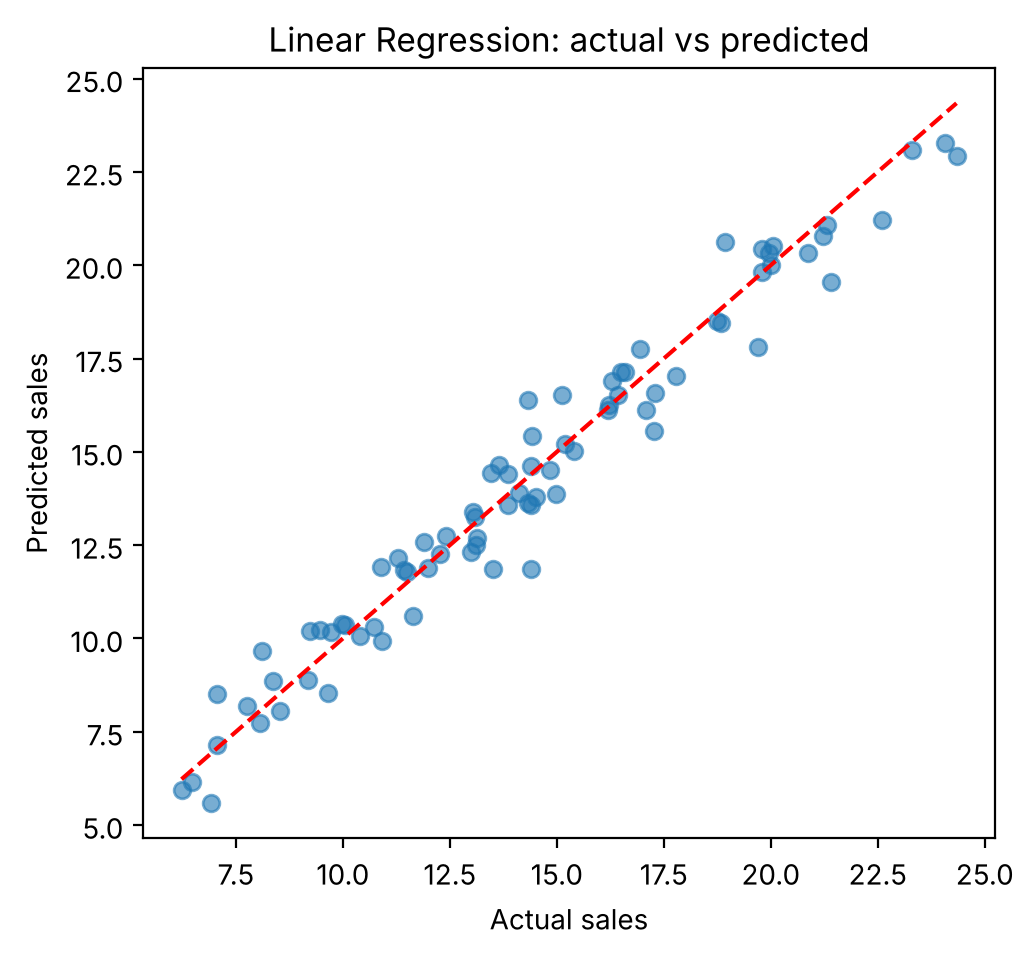

In [4]:
best_name = results.iloc[0]['Model']; best = models[best_name]
pred = best.predict(X_test)
print('Best model:', best_name)

lin = models['Linear Regression']
print('\nLinear model: Sales = %.3f + %.4f*TV + %.4f*Radio + %.4f*Newspaper'
      % (lin.intercept_, *lin.coef_))

plt.figure(figsize=(5.5, 5))
plt.scatter(y_test, pred, alpha=0.6)
lim = [y_test.min(), y_test.max()]; plt.plot(lim, lim, 'r--')
plt.xlabel('Actual sales'); plt.ylabel('Predicted sales'); plt.title(f'{best_name}: actual vs predicted')
plt.show()

In [5]:
# Forecast sales for future advertising plans
future = pd.DataFrame({'TV': [120, 200, 280, 280], 'Radio': [10, 25, 40, 5], 'Newspaper': [20, 40, 60, 90]})
future['Predicted_Sales'] = best.predict(future).round(2)
print('Future sales forecast (units) for planned budgets:')
future

Future sales forecast (units) for planned budgets:


,TV,Radio,Newspaper,Predicted_Sales
0,120,10,20,10.48
1,200,25,40,17.20
2,280,40,60,23.92
3,280,5,90,17.27


## Result
TV and Radio spending are the main drivers of sales, while Newspaper spending contributes very little. The best model (selected by test R2 and cross-validation) was used to forecast sales for future advertising budgets.